# Exploratory Data Analysis on Superstore Retail Sales
**Datheon Data Analytics & Power BI Internship, Task 1**

**Author:** Promise Jeneka Taiwo

**Goal:** Clean the Superstore sales data, check for missing values, and find out what the numbers say about customer purchases, monthly seasonality, category revenue and discount sensitivity.

**Tools:** Python (Pandas, Matplotlib, Seaborn) in Jupyter Notebook

## 1. Loading the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

raw = pd.read_csv("superstore_sales.csv", encoding="latin1")
print("Shape:", raw.shape)
raw.head()

Shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters by Universal,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


## 2. Data cleaning

The file has 10,800 rows, but the real sales records should be around 10,000. I checked the bottom of the file to see what the extra rows are.

In [2]:
raw.tail(10)[["Row ID", "Order ID", "Order Date", "Sales"]]

,Row ID,Order ID,Order Date,Sales
10790,Yes,US-2018-147886,NaN,NaN
10791,Yes,US-2018-147886,NaN,NaN
10792,Yes,US-2018-147886,NaN,NaN
10793,Yes,US-2018-147886,NaN,NaN
10794,Yes,US-2018-147886,NaN,NaN
10795,Yes,US-2018-147886,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN


The last rows are not sales records. The Superstore "People" table (salesperson per region) and "Returns" table (returned order IDs) were pasted below the sales data, so they got read into the wrong columns. I will pull the returns out first, because they are useful later, and then drop everything that is not a real sales row.

In [3]:
# Returns block: rows where "Row ID" says "Yes" and "Order ID" holds the returned order
returned_ids = set(raw.loc[raw["Row ID"] == "Yes", "Order ID"])
print("Unique returned orders:", len(returned_ids))

# Keep only real sales rows (they are the ones with a Sales value)
df = raw[raw["Sales"].notna()].copy()
print("Rows after removing the pasted tables:", len(df))

Unique returned orders: 296
Rows after removing the pasted tables: 9994


In [4]:
# Missing values and data types after the removal
print(df.isna().sum()[df.isna().sum() > 0])
print()
df.dtypes

Postal Code    11
dtype: int64



,0
Row ID,str
Order ID,str
Order Date,str
Ship Date,str
Ship Mode,str
Customer ID,str
Customer Name,str
Segment,str
Country,str
City,str


Only **Postal Code** has missing values (11 rows). I checked which city they belong to.

In [5]:
df.loc[df["Postal Code"].isna(), ["City", "State"]].drop_duplicates()

,City,State
2234,Burlington,Vermont


All 11 are Burlington, Vermont, which just has no postal code in the source file. I filled it with 05401, the main Burlington ZIP code. Postal code is not used in any calculation here, so this does not change the results.

In [6]:
df["Postal Code"] = df["Postal Code"].fillna(5401)
df["Postal Code"] = df["Postal Code"].astype(int).astype(str).str.zfill(5)

# Fix data types
df["Row ID"] = df["Row ID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

# Duplicates
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicates ignoring Row ID:", df.drop(columns="Row ID").duplicated().sum())

Fully duplicated rows: 0
Duplicates ignoring Row ID: 1


There is one row that repeats another one exactly (apart from Row ID). It is a single line out of about 10,000, so I removed it to be safe.

In [7]:
df = df.drop_duplicates(subset=df.columns.drop("Row ID")).reset_index(drop=True)

# New columns for the analysis
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M")
df["Profit Margin %"] = df["Profit"] / df["Sales"] * 100
df["Returned"] = df["Order ID"].isin(returned_ids)

print("Clean dataset:", df.shape)
print("Date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
df.describe()[["Sales", "Quantity", "Discount", "Profit"]].round(2)

Clean dataset: (9993, 26)
Date range: 2015-01-03 to 2018-12-30


,Sales,Quantity,Discount,Profit
count,9993.00,9993.00,9993.00,9993.00
mean,229.85,3.79,0.16,28.66
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.48,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98
std,623.28,2.23,0.21,234.27


## 3. Overall picture

In [8]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
print(f"Total sales:   ${total_sales:,.0f}")
print(f"Total profit:  ${total_profit:,.0f}")
print(f"Overall margin: {total_profit / total_sales * 100:.1f}%")
print(f"Orders: {df['Order ID'].nunique():,}  |  Customers: {df['Customer ID'].nunique():,}  |  Products: {df['Product ID'].nunique():,}")

Total sales:   $2,296,919
Total profit:  $286,409
Overall margin: 12.5%
Orders: 5,009  |  Customers: 793  |  Products: 1,862


## 4. Customer purchase volume

In [9]:
cust = df.groupby(["Customer ID", "Customer Name"]).agg(
    Orders=("Order ID", "nunique"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
).reset_index()

print("Top 10 customers by sales")
display(cust.sort_values("Sales", ascending=False).head(10).round(2))

top10_share = cust.nlargest(int(len(cust) * 0.1), "Sales")["Sales"].sum() / cust["Sales"].sum() * 100
print(f"\nThe top 10% of customers bring in {top10_share:.1f}% of all sales.")
print(f"Customers with negative total profit: {(cust['Profit'] < 0).sum()} of {len(cust)}")

Top 10 customers by sales


,Customer ID,Customer Name,Orders,Sales,Profit
700,SM-20320,Sean Miller,5,25043.05,-1980.74
741,TC-20980,Tamara Chand,5,19052.22,8981.32
621,RB-19360,Raymond Buch,6,15117.34,6976.10
730,TA-21385,Tom Ashbrook,4,14595.62,4703.79
6,AB-10105,Adrian Barton,10,14473.57,5444.81
434,KL-16645,Ken Lonsdale,12,14175.23,806.86
669,SC-20095,Sanjit Chand,9,14142.33,5757.41
327,HL-15040,Hunter Lopez,6,12873.30,5622.43
683,SE-20110,Sanjit Engle,11,12209.44,2650.68
131,CC-12370,Christopher Conant,5,12129.07,2177.05



The top 10% of customers bring in 30.6% of all sales.
Customers with negative total profit: 155 of 793


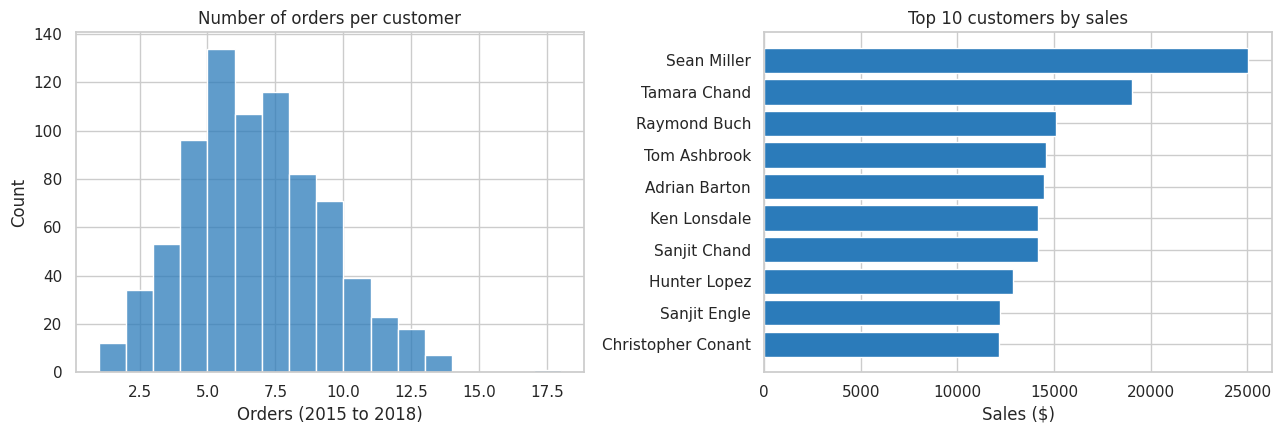

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(cust["Orders"], bins=range(1, cust["Orders"].max() + 2), ax=ax[0], color="#2b7bba")
ax[0].set_title("Number of orders per customer")
ax[0].set_xlabel("Orders (2015 to 2018)")

top = cust.nlargest(10, "Sales").sort_values("Sales")
ax[1].barh(top["Customer Name"], top["Sales"], color="#2b7bba")
ax[1].set_title("Top 10 customers by sales")
ax[1].set_xlabel("Sales ($)")
plt.tight_layout()
plt.show()

## 5. Monthly seasonality

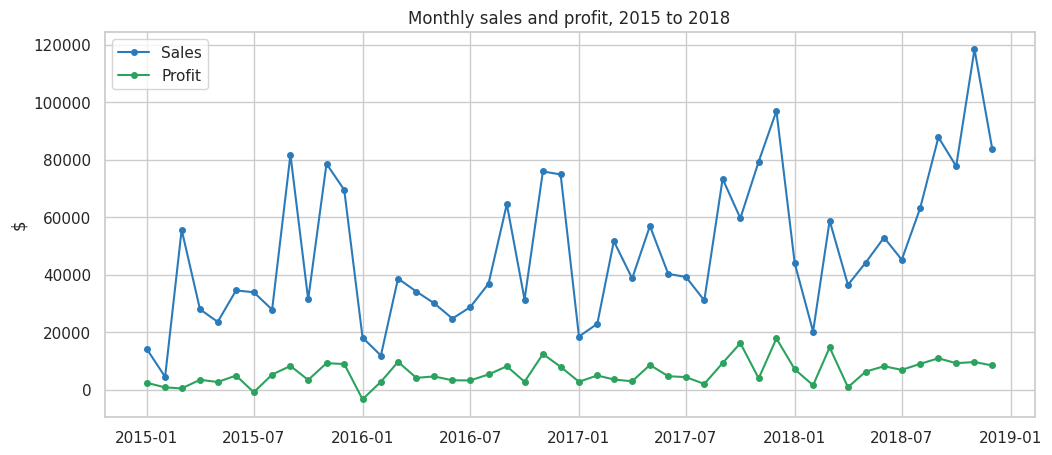

In [11]:
monthly = df.groupby("Year-Month")[["Sales", "Profit"]].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly["Sales"], marker="o", ms=4, label="Sales", color="#2b7bba")
ax.plot(monthly.index, monthly["Profit"], marker="o", ms=4, label="Profit", color="#2ca25f")
ax.set_title("Monthly sales and profit, 2015 to 2018")
ax.set_ylabel("$")
ax.legend()
plt.show()

September, November and December make up 42.9% of total sales.
Strongest month on average: Nov
Weakest month on average:   Feb


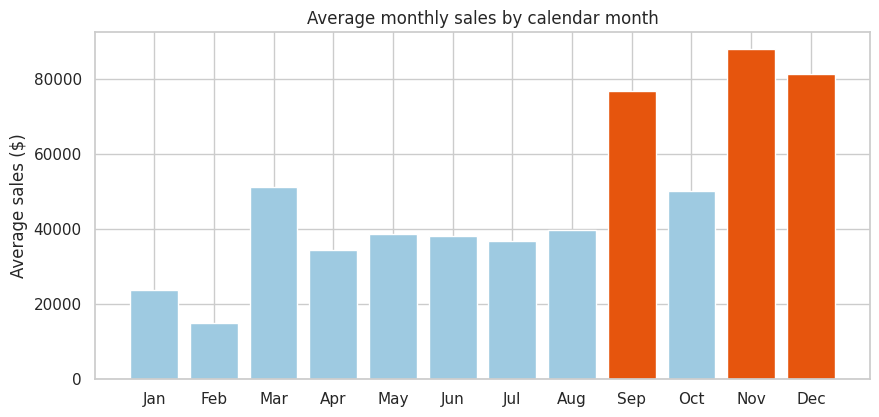

,Sales,Profit,Sales growth %
Year,,,
2015,483966.1,49556.0,NaN
2016,470532.5,61618.6,-2.8
2017,609205.6,81795.2,29.5
2018,733215.3,93439.3,20.4


In [12]:
# Average by calendar month, using the years 2015 to 2018
by_month = df.groupby(["Year", "Month"])["Sales"].sum().groupby("Month").mean()
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(month_names, by_month.values, color=["#e6550d" if m in (9, 11, 12) else "#9ecae1" for m in by_month.index])
ax.set_title("Average monthly sales by calendar month")
ax.set_ylabel("Average sales ($)")
plt.show()

q4 = df[df["Month"].isin([9, 11, 12])]["Sales"].sum() / df["Sales"].sum() * 100
print(f"September, November and December make up {q4:.1f}% of total sales.")
print("Strongest month on average:", month_names[by_month.idxmax() - 1])
print("Weakest month on average:  ", month_names[by_month.idxmin() - 1])

yearly = df.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Sales growth %"] = yearly["Sales"].pct_change() * 100
yearly.round(1)

## 6. Category and region revenue

In [13]:
cat = df.groupby("Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
cat["Margin %"] = cat["Profit"] / cat["Sales"] * 100
cat.round(1)

,Sales,Profit,Margin %
Category,,,
Furniture,741718.4,18463.3,2.5
Office Supplies,719047.0,122490.8,17.0
Technology,836154.0,145454.9,17.4


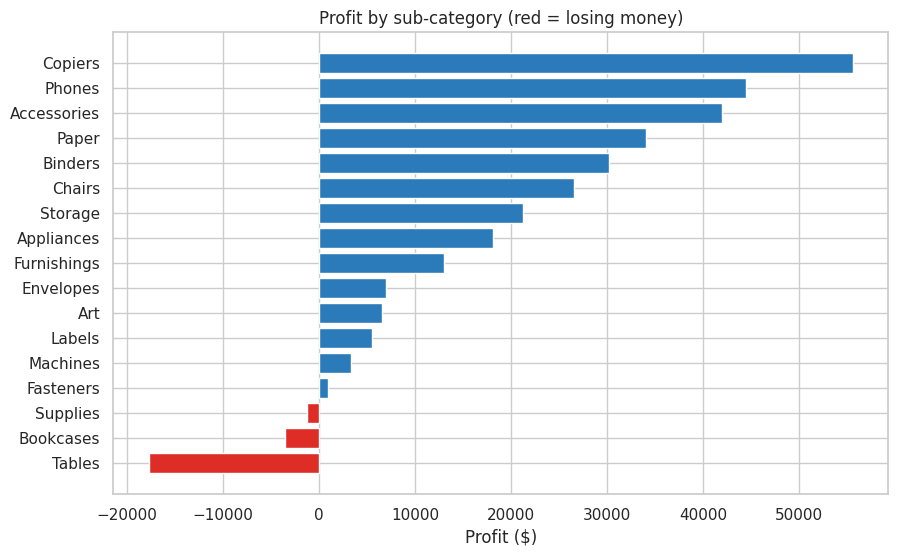

,Sales,Profit,Margin %
Sub-Category,,,
Tables,206965.5,-17725.5,-8.6
Bookcases,114880.0,-3472.6,-3.0
Supplies,46673.5,-1189.1,-2.5
Fasteners,3024.3,949.5,31.4
Machines,189238.6,3384.8,1.8


In [14]:
sub = df.groupby("Sub-Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).sort_values("Profit")
sub["Margin %"] = sub["Profit"] / sub["Sales"] * 100

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#de2d26" if p < 0 else "#2b7bba" for p in sub["Profit"]]
ax.barh(sub.index, sub["Profit"], color=colors)
ax.set_title("Profit by sub-category (red = losing money)")
ax.set_xlabel("Profit ($)")
plt.show()

sub.sort_values("Profit").round(1).head(5)

In [15]:
region = df.groupby("Region").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
region["Margin %"] = region["Profit"] / region["Sales"] * 100
seg = df.groupby("Segment").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
seg["Margin %"] = seg["Profit"] / seg["Sales"] * 100
display(region.round(1))
display(seg.round(1))

,Sales,Profit,Margin %
Region,,,
Central,501239.9,39706.4,7.9
East,678499.9,91534.8,13.5
South,391721.9,46749.4,11.9
West,725457.8,108418.4,14.9


,Sales,Profit,Margin %
Segment,,,
Consumer,1161401.3,134119.2,11.5
Corporate,706146.4,91979.1,13.0
Home Office,429371.8,60310.7,14.0


## 7. Discount sensitivity

Correlation between discount and profit: -0.219


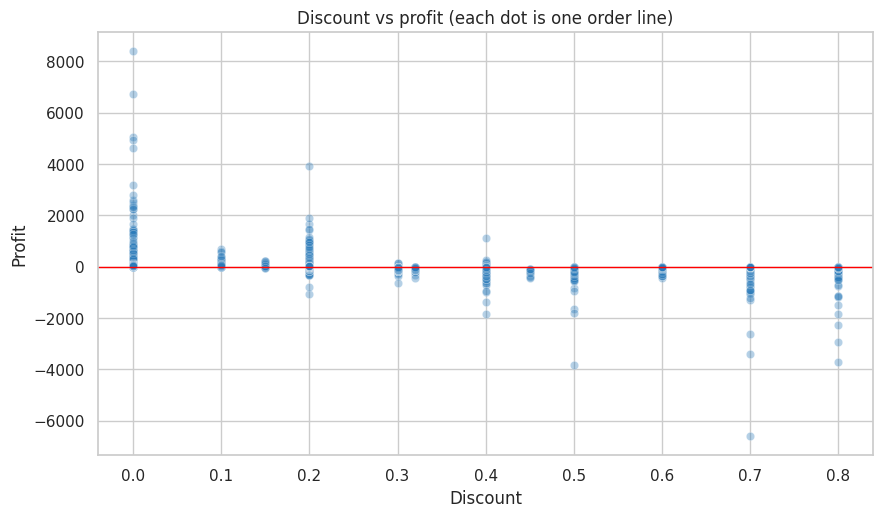

In [16]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.35, ax=ax, color="#2b7bba")
ax.axhline(0, color="red", lw=1)
ax.set_title("Discount vs profit (each dot is one order line)")
plt.show()

print("Correlation between discount and profit:", round(df["Discount"].corr(df["Profit"]), 3))

In [17]:
bins = [-0.01, 0, 0.2, 0.4, 1.0]
labels = ["No discount", "1 to 20%", "21 to 40%", "Above 40%"]
df["Discount Band"] = pd.cut(df["Discount"], bins=bins, labels=labels)

band = df.groupby("Discount Band", observed=True).agg(
    Lines=("Sales", "size"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
)
band["Margin %"] = band["Profit"] / band["Sales"] * 100
band["Share of lines that lose money %"] = df.groupby("Discount Band", observed=True)["Profit"].apply(lambda s: (s < 0).mean() * 100)
band.round(1)

,Lines,Sales,Profit,Margin %,Share of lines that lose money %
Discount Band,,,,,
No discount,4798,1087908.5,320987.6,29.5,0.0
1 to 20%,3803,846522.2,100785.5,11.9,13.8
21 to 40%,459,233856.5,-35805.4,-15.3,90.2
Above 40%,933,128632.3,-99558.6,-77.4,100.0


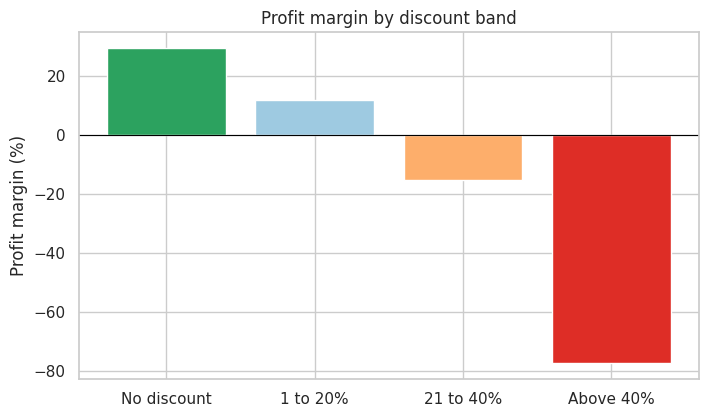

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(band.index.astype(str), band["Margin %"], color=["#2ca25f", "#9ecae1", "#fdae6b", "#de2d26"])
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Profit margin by discount band")
ax.set_ylabel("Profit margin (%)")
plt.show()

## 8. Returns

In [19]:
ret_orders = df.groupby("Order ID")["Returned"].max()
print(f"Orders returned: {ret_orders.sum()} of {len(ret_orders)} ({ret_orders.mean() * 100:.1f}%)")
print(f"Sales value tied to returned orders: ${df.loc[df['Returned'], 'Sales'].sum():,.0f} "
      f"({df.loc[df['Returned'], 'Sales'].sum() / df['Sales'].sum() * 100:.1f}% of sales)")

Orders returned: 296 of 5009 (5.9%)
Sales value tied to returned orders: $180,504 (7.9% of sales)


## 9. Executive takeaways


Here are the five main things I found in the data.

**1. A small group of customers carries a big part of the revenue, and some of them cost money.**
The top 10% of customers (about 79 people) bring in 30.6% of all sales. But 155 of the 793 customers have a negative total profit. The clearest example is Sean Miller, who is the biggest customer by sales ($25,043) but lost $1,981. One order of Machines with a 50% discount lost $1,811 on its own.

**2. Sales are very seasonal, and the second half of the year does most of the work.**
September, November and December together make up 42.9% of all sales. November is the strongest month on average and February is the weakest. Sales dipped slightly in 2016 (-2.8%) and then grew 29.5% in 2017 and 20.4% in 2018, so the business is growing overall.

**3. Furniture sells a lot but earns almost nothing.**
Furniture has $741,718 in sales but only a 2.5% margin, while Technology (17.4%) and Office Supplies (17.0%) are much healthier. Inside Furniture, Tables lost $17,726 in total and Bookcases lost $3,473. Supplies also lost money outside Furniture. Machines have $189,239 in sales but earn only a 1.8% margin.

**4. Discounts are the biggest threat to profit.**
Orders with no discount earn a 29.5% margin. At 1 to 20% off the margin falls to 11.9%, at 21 to 40% it becomes negative (-15.3%), and above 40% it is -77.4%. Every single order line with more than 40% discount lost money. About 14% of all order lines have a discount above 20%, and together they lost around $135,000. The correlation between discount and profit is -0.22.

**5. The Central region is the weakest, and it also discounts the most.**
Central has an average discount of 24%, compared with 11% in the West, and its profit margin is only 7.9% against 14.9% in the West. Returns are a smaller problem: 5.9% of orders were returned, which is 7.9% of sales value.

**Suggested actions:** put a cap of around 20% on discounts, review the pricing of Tables, Bookcases and Supplies, check why Central discounts so heavily, and make sure there is enough stock and marketing support ahead of September to December.
